# 06 - معالجة الفيديو إطارًا بإطار

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

في هذا الدفتر سنطبق خوارزميات معالجة الصور السابقة على الفيديو، حيث يُقرأ الفيديو كسلسلة من الإطارات، ويُعالج كل إطار ثم يُكتب في فيديو جديد.

## أهداف الدفتر

1. قراءة الفيديو والحصول على الدقة وFPS وعدد الإطارات والمدة.
2. استخراج إطارات من أزمنة مختلفة وعرضها.
3. تطبيق Grayscale وBlur وSharpen وCanny وThreshold وHSV وHough Lines.
4. معاينة تأثير الخوارزمية على إطار واحد قبل معالجة الفيديو كاملًا.
5. معالجة الفيديو إطارًا بإطار مع عرض التقدم والسرعة.
6. حفظ فيديو MP4 متوافق مع المتصفح، والاحتفاظ بالصوت الأصلي عند توفر FFmpeg.
7. إعادة استخدام فيديوهات Drive دون رفعها في كل تشغيل.

> بسبب سرعة الرفع المحدودة، استخدم فيديو اختبار قصيرًا من 10 إلى 20 ثانية، ويفضل أن يكون بدقة 480p أو 720p وحجمه أقل من 10 MB.

## 1. استيراد المكتبات وربط Google Drive

In [ ]:
from pathlib import Path
import shutil
import subprocess
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/06_Video_Processing'
)
FRAME_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/06_Video_Frames'
)

VIDEO_INPUT_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FRAME_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Video input directory:', VIDEO_INPUT_DIR)
print('Video output directory:', VIDEO_OUTPUT_DIR)
print('Frame output directory:', FRAME_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Video input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input
Video output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/06_Video_Processing
Frame output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/06_Video_Frames


## 2. دوال العرض ومعلومات الفيديو

In [ ]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_frames(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, frame) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(frame),
            cmap='gray' if frame.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def get_video_info(video_path):
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {video_path}')

    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    capture.release()

    if fps <= 0:
        fps = 25.0
    duration = frame_count / fps if frame_count > 0 else 0.0

    return {
        'width': width,
        'height': height,
        'fps': fps,
        'frame_count': frame_count,
        'duration_seconds': duration,
        'size_mb': Path(video_path).stat().st_size / (1024 * 1024)
    }


def print_video_info(video_path, info):
    print('Video:', Path(video_path).name)
    print(f"Resolution: {info['width']} x {info['height']}")
    print(f"FPS: {info['fps']:.2f}")
    print(f"Frames: {info['frame_count']}")
    print(f"Duration: {info['duration_seconds']:.2f} seconds")
    print(f"File size: {info['size_mb']:.2f} MB")

## 3. دوال قراءة الإطارات وإنشاء فيديو اختبار

In [ ]:
def read_frame(video_path, frame_number=0):
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {video_path}')

    capture.set(cv2.CAP_PROP_POS_FRAMES, max(0, int(frame_number)))
    success, frame = capture.read()
    capture.release()

    if not success or frame is None:
        raise ValueError(f'تعذر قراءة الإطار رقم {frame_number}.')
    return frame


def extract_sample_frames(video_path, number_of_frames=4):
    info = get_video_info(video_path)
    total = max(1, info['frame_count'])
    count = max(1, min(int(number_of_frames), total))
    indices = np.linspace(0, total - 1, count, dtype=int)

    frames = {}
    for index in indices:
        try:
            frames[f'Frame {index}'] = read_frame(video_path, index)
        except ValueError:
            continue
    return frames


def create_test_video(output_path, width=640, height=360, fps=15, seconds=5):
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(
        str(output_path), fourcc, float(fps), (int(width), int(height))
    )
    if not writer.isOpened():
        raise RuntimeError('تعذر إنشاء فيديو الاختبار.')

    total_frames = int(fps * seconds)
    for frame_index in range(total_frames):
        frame = np.full((height, width, 3), 235, dtype=np.uint8)
        progress = frame_index / max(1, total_frames - 1)
        circle_x = int(60 + progress * (width - 120))
        rectangle_y = int(40 + progress * 170)

        cv2.circle(frame, (circle_x, 100), 45, (20, 40, 220), -1)
        cv2.rectangle(
            frame, (360, rectangle_y),
            (520, rectangle_y + 90), (40, 180, 40), -1
        )
        cv2.line(frame, (40, 300), (600, 230), (30, 30, 30), 6)
        cv2.putText(
            frame, f'Frame {frame_index}', (20, 340),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8,
            (20, 20, 20), 2, cv2.LINE_AA
        )
        writer.write(frame)

    writer.release()
    return output_path

## 4. خوارزميات معالجة إطار الفيديو

In [ ]:
PROCESSING_MODES = [
    'original',
    'grayscale',
    'gaussian_blur',
    'median_blur',
    'sharpen',
    'canny',
    'threshold',
    'hsv_isolation',
    'hough_lines'
]


def resize_frame_max_width(frame, maximum_width=None):
    resized = frame
    height, width = frame.shape[:2]
    if maximum_width is not None and int(maximum_width) > 0:
        maximum_width = int(maximum_width)
        if width > maximum_width:
            scale = maximum_width / width
            new_height = max(2, int(round(height * scale)))
            resized = cv2.resize(
                frame, (maximum_width, new_height),
                interpolation=cv2.INTER_AREA
            )

    # أغلب مرمّزات MP4 تتطلب أبعادًا زوجية.
    resized_height, resized_width = resized.shape[:2]
    even_height = max(2, resized_height - resized_height % 2)
    even_width = max(2, resized_width - resized_width % 2)
    return resized[:even_height, :even_width]


def sharpen_frame(frame):
    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ], dtype=np.float32)
    return cv2.filter2D(frame, -1, kernel)


def canny_frame(frame, low_threshold=100, high_threshold=200):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(
        blurred,
        max(0, int(low_threshold)),
        max(int(low_threshold) + 1, int(high_threshold))
    )
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)


def threshold_frame(frame, threshold_value=127):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(
        gray, int(np.clip(threshold_value, 0, 255)),
        255, cv2.THRESH_BINARY
    )
    return cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)


def isolate_hsv_color(
    frame, lower_hsv=(0, 70, 50), upper_hsv=(20, 255, 255)
):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(
        hsv,
        np.array(lower_hsv, dtype=np.uint8),
        np.array(upper_hsv, dtype=np.uint8)
    )
    return cv2.bitwise_and(frame, frame, mask=mask)


def hough_lines_frame(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    lines = cv2.HoughLinesP(
        edges, 1, np.pi / 180,
        threshold=40, minLineLength=50, maxLineGap=12
    )

    result = frame.copy()
    if lines is not None:
        for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
            cv2.line(
                result,
                (int(x1), int(y1)), (int(x2), int(y2)),
                (0, 0, 255), 3
            )
    return result


def process_frame(
    frame,
    mode='canny',
    low_threshold=100,
    high_threshold=200,
    threshold_value=127,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
):
    if mode not in PROCESSING_MODES:
        raise ValueError(f'وضع المعالجة غير معروف: {mode}')

    if mode == 'original':
        return frame.copy()
    if mode == 'grayscale':
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    if mode == 'gaussian_blur':
        return cv2.GaussianBlur(frame, (7, 7), 0)
    if mode == 'median_blur':
        return cv2.medianBlur(frame, 7)
    if mode == 'sharpen':
        return sharpen_frame(frame)
    if mode == 'canny':
        return canny_frame(frame, low_threshold, high_threshold)
    if mode == 'threshold':
        return threshold_frame(frame, threshold_value)
    if mode == 'hsv_isolation':
        return isolate_hsv_color(frame, lower_hsv, upper_hsv)
    return hough_lines_frame(frame)

## 5. دالة معالجة الفيديو وحفظه

In [ ]:
def process_video(
    input_path,
    output_path,
    mode='canny',
    maximum_width=640,
    max_seconds=None,
    progress_every=30,
    **processing_parameters
):
    capture = cv2.VideoCapture(str(input_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {input_path}')

    source_fps = float(capture.get(cv2.CAP_PROP_FPS))
    if source_fps <= 0:
        source_fps = 25.0
    source_frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))

    success, first_frame = capture.read()
    if not success or first_frame is None:
        capture.release()
        raise ValueError('الفيديو لا يحتوي على إطار صالح.')

    first_frame = resize_frame_max_width(first_frame, maximum_width)
    processed_first = process_frame(
        first_frame, mode=mode, **processing_parameters
    )
    output_height, output_width = processed_first.shape[:2]

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(
        str(output_path), fourcc, source_fps,
        (output_width, output_height)
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError(f'تعذر إنشاء الفيديو الناتج: {output_path}')

    maximum_frames = None
    if max_seconds is not None and float(max_seconds) > 0:
        maximum_frames = int(float(max_seconds) * source_fps)

    start_time = time.perf_counter()
    processed_count = 0

    writer.write(processed_first)
    processed_count += 1

    while True:
        if maximum_frames is not None and processed_count >= maximum_frames:
            break

        success, frame = capture.read()
        if not success or frame is None:
            break

        frame = resize_frame_max_width(frame, maximum_width)
        processed = process_frame(
            frame, mode=mode, **processing_parameters
        )
        writer.write(processed)
        processed_count += 1

        if progress_every and processed_count % int(progress_every) == 0:
            if source_frame_count > 0:
                percent = 100 * processed_count / source_frame_count
                print(
                    f'Processed {processed_count}/{source_frame_count} '
                    f'frames ({min(percent, 100):.1f}%)'
                )
            else:
                print(f'Processed {processed_count} frames')

    capture.release()
    writer.release()

    elapsed = time.perf_counter() - start_time
    processing_fps = processed_count / elapsed if elapsed > 0 else 0.0

    return {
        'frames_processed': processed_count,
        'source_fps': source_fps,
        'processing_fps': processing_fps,
        'elapsed_seconds': elapsed,
        'output_width': output_width,
        'output_height': output_height
    }


def finalize_mp4(silent_video_path, original_video_path, final_video_path):
    ffmpeg_path = shutil.which('ffmpeg')
    if ffmpeg_path is None:
        shutil.copy2(silent_video_path, final_video_path)
        return False, 'FFmpeg غير متاح؛ حُفظ فيديو OpenCV بدون صوت.'

    command = [
        ffmpeg_path, '-y',
        '-i', str(silent_video_path),
        '-i', str(original_video_path),
        '-map', '0:v:0',
        '-map', '1:a?',
        '-c:v', 'libx264',
        '-preset', 'fast',
        '-crf', '23',
        '-pix_fmt', 'yuv420p',
        '-c:a', 'aac',
        '-b:a', '128k',
        '-shortest',
        '-movflags', '+faststart',
        str(final_video_path)
    ]

    try:
        subprocess.run(
            command,
            check=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )
        return True, 'تم إنشاء MP4 متوافق مع المتصفح وإضافة الصوت إن وُجد.'
    except subprocess.CalledProcessError as error:
        shutil.copy2(silent_video_path, final_video_path)
        details = error.stderr.decode('utf-8', errors='ignore')[-500:]
        print('FFmpeg warning:', details)
        return False, 'تعذر التحويل؛ حُفظ فيديو OpenCV بدون صوت.'

## 6. قراءة فيديوهات Drive أو رفع فيديو جديد اختياريًا

- اترك `UPLOAD_NEW_FILES = False` في التشغيل المعتاد.
- غيّره إلى `True` فقط عند إضافة فيديو جديد.
- الفيديو المرفوع يُحفظ في Drive ثم يعاد استخدامه لاحقًا.
- إذا لم يوجد فيديو، ينشئ الدفتر فيديو اختبار صغيرًا تلقائيًا.

In [ ]:
UPLOAD_NEW_FILES = False
SUPPORTED_VIDEO_EXTENSIONS = {
    '.mp4', '.avi', '.mov', '.mkv', '.webm', '.m4v'
}


def scan_videos(directory):
    return [
        path for path in sorted(directory.iterdir())
        if path.is_file()
        and path.suffix.lower() in SUPPORTED_VIDEO_EXTENSIONS
    ]


video_paths = scan_videos(VIDEO_INPUT_DIR)

if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    uploaded = files.upload()
    for file_name, file_data in uploaded.items():
        suffix = Path(file_name).suffix.lower()
        if suffix not in SUPPORTED_VIDEO_EXTENSIONS:
            print(f'تم تجاهل ملف غير مدعوم: {file_name}')
            continue

        safe_name = Path(file_name).name
        destination = VIDEO_INPUT_DIR / safe_name
        destination.write_bytes(file_data)
        print('Saved:', destination)

    video_paths = scan_videos(VIDEO_INPUT_DIR)

if not video_paths:
    generated_path = VIDEO_INPUT_DIR / 'video_processing_test.mp4'
    create_test_video(generated_path)
    video_paths = [generated_path]
    print('لم توجد فيديوهات؛ تم إنشاء فيديو اختبار تلقائيًا.')

print(f'عدد الفيديوهات المتاحة: {len(video_paths)}')
for path in video_paths:
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f'- {path.name}: {size_mb:.2f} MB')

عدد الفيديوهات المتاحة: 3
- dog.mp4: 3.17 MB
- kitten.mp4: 2.74 MB
- video_processing_test.mp4: 0.16 MB


## 7. اختيار الفيديو وعرض معلوماته

In [ ]:
# اتركه فارغًا لاختيار أول فيديو، أو اكتب اسم الملف كاملًا.
SELECTED_VIDEO_NAME = ''

video_by_name = {path.name: path for path in video_paths}

if SELECTED_VIDEO_NAME:
    if SELECTED_VIDEO_NAME not in video_by_name:
        available = ', '.join(video_by_name)
        raise ValueError(
            f'الفيديو غير موجود. الفيديوهات المتاحة: {available}'
        )
    selected_video_path = video_by_name[SELECTED_VIDEO_NAME]
else:
    selected_video_path = video_paths[0]

selected_video_info = get_video_info(selected_video_path)
print_video_info(selected_video_path, selected_video_info)

Video: dog.mp4
Resolution: 1280 x 720
FPS: 29.97
Frames: 336
Duration: 11.21 seconds
File size: 3.17 MB


## 8. استخراج إطارات من الفيديو

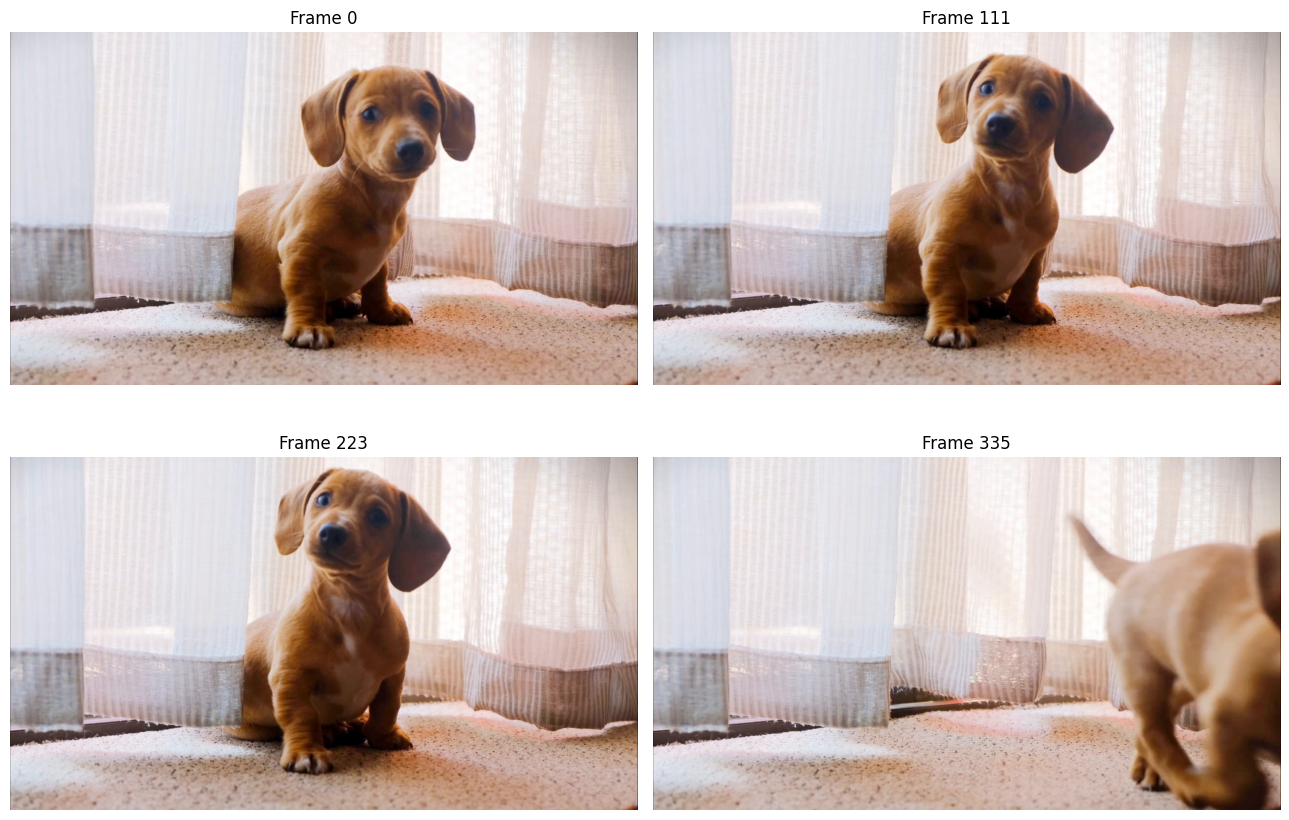

In [ ]:
sample_frames = extract_sample_frames(
    selected_video_path,
    number_of_frames=4
)

show_frames(
    sample_frames,
    columns=2,
    figure_width=13
)

## 9. مقارنة طرق المعالجة على إطار واحد

المعاينة على إطار واحد مهمة قبل معالجة الفيديو كاملًا؛ لأنها تتيح اختيار الخوارزمية والمعاملات بسرعة دون الانتظار.

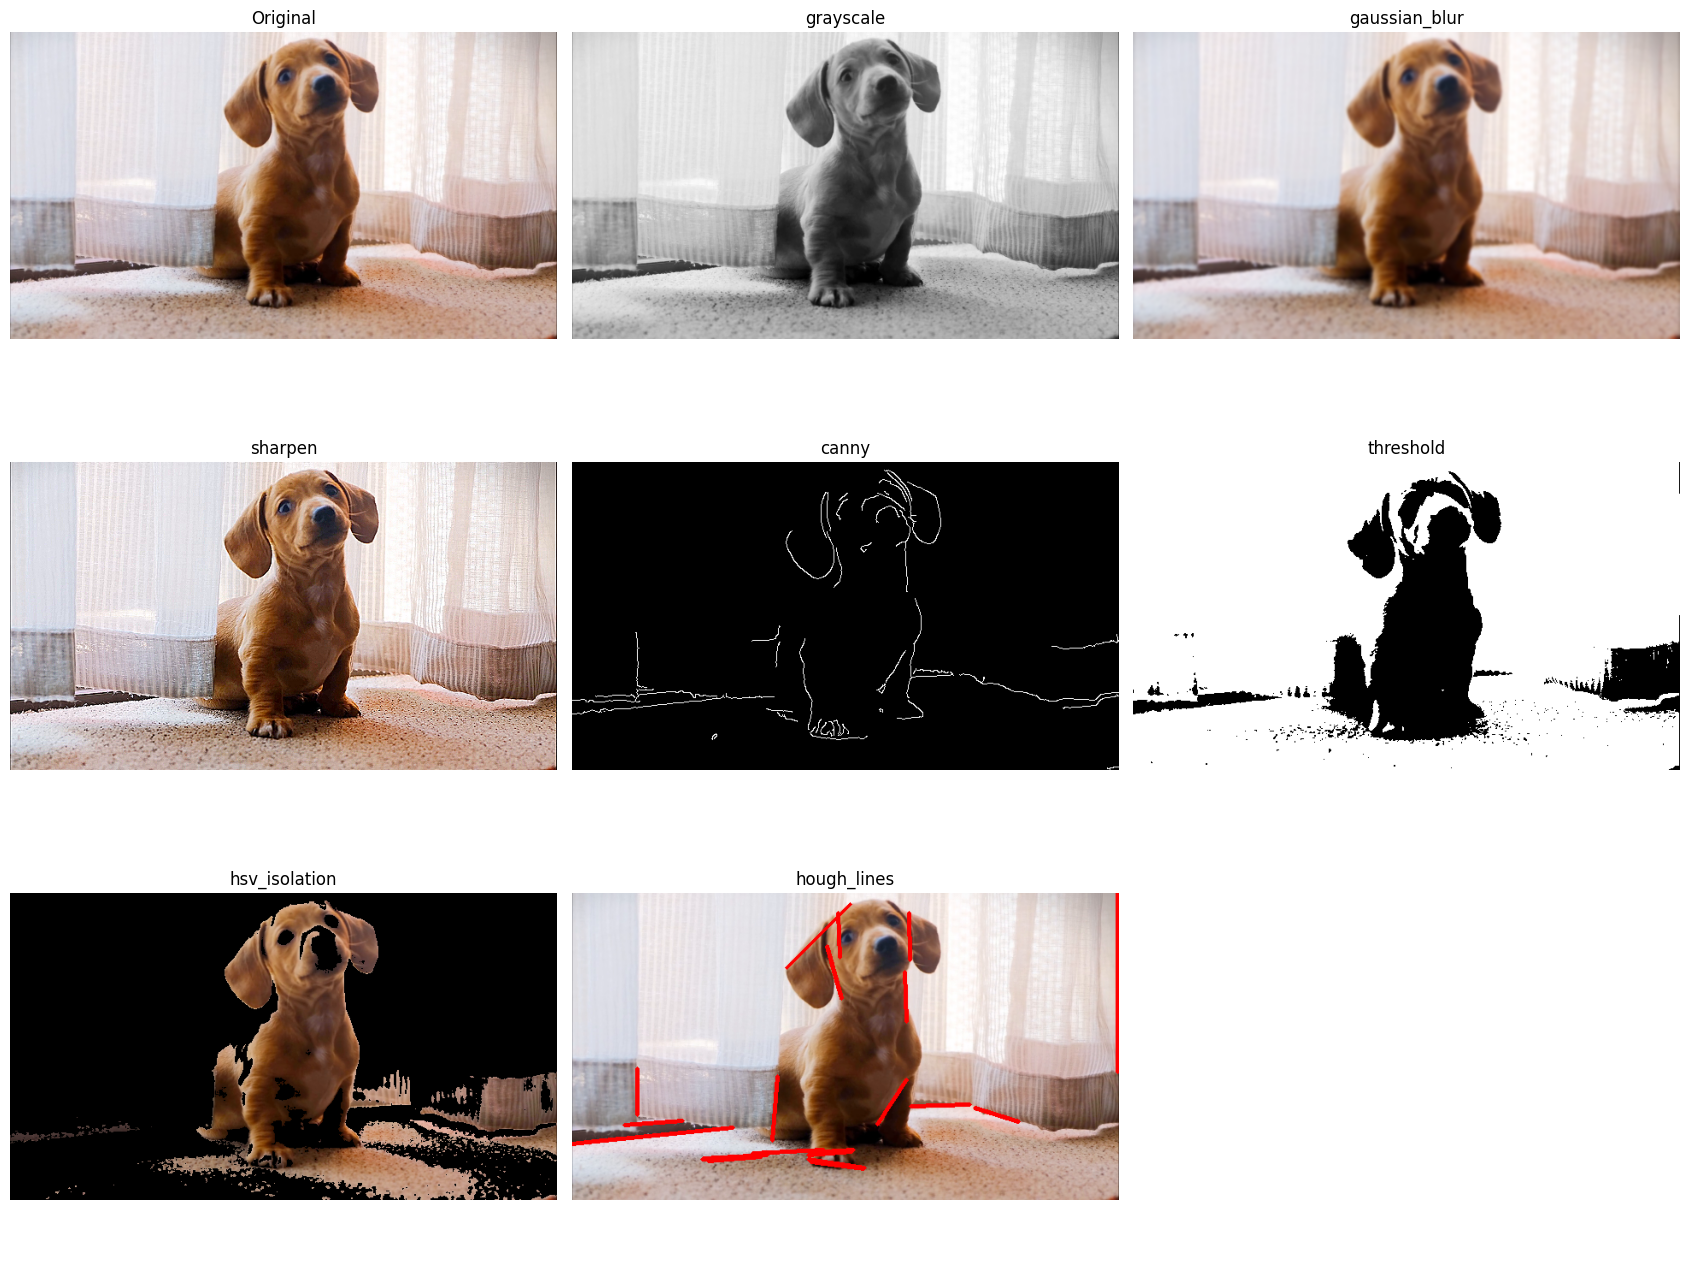

In [ ]:
middle_frame_number = max(
    0, selected_video_info['frame_count'] // 2
)
preview_frame = read_frame(
    selected_video_path,
    middle_frame_number
)
preview_frame = resize_frame_max_width(preview_frame, 640)

preview_results = {'Original': preview_frame}
for mode in [
    'grayscale', 'gaussian_blur', 'sharpen',
    'canny', 'threshold', 'hsv_isolation', 'hough_lines'
]:
    preview_results[mode] = process_frame(preview_frame, mode=mode)

show_frames(
    preview_results,
    columns=3,
    figure_width=17
)

## 10. أداة المعاينة التفاعلية

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_video_preview(
    mode='canny',
    frame_number=0,
    low_threshold=100,
    high_threshold=200,
    threshold_value=127,
    h_low=0,
    h_high=20
):
    current_frame = read_frame(selected_video_path, frame_number)
    current_frame = resize_frame_max_width(current_frame, 640)
    low_h = min(int(h_low), int(h_high))
    high_h = max(int(h_low), int(h_high))

    processed = process_frame(
        current_frame,
        mode=mode,
        low_threshold=low_threshold,
        high_threshold=high_threshold,
        threshold_value=threshold_value,
        lower_hsv=(low_h, 70, 50),
        upper_hsv=(high_h, 255, 255)
    )

    show_frames(
        {
            f'Original Frame {frame_number}': current_frame,
            f'Processed: {mode}': processed
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    maximum_frame = max(0, selected_video_info['frame_count'] - 1)
    preview_controls = widgets.interactive(
        interactive_video_preview,
        mode=widgets.Dropdown(
            options=PROCESSING_MODES,
            value='canny', description='Mode'
        ),
        frame_number=widgets.IntSlider(
            value=min(middle_frame_number, maximum_frame),
            min=0, max=maximum_frame,
            step=max(1, maximum_frame // 100),
            description='Frame'
        ),
        low_threshold=widgets.IntSlider(
            value=100, min=0, max=255, step=5,
            description='Canny Low'
        ),
        high_threshold=widgets.IntSlider(
            value=200, min=1, max=255, step=5,
            description='Canny High'
        ),
        threshold_value=widgets.IntSlider(
            value=127, min=0, max=255, step=1,
            description='Threshold'
        ),
        h_low=widgets.IntSlider(
            value=0, min=0, max=179, step=1,
            description='H Low'
        ),
        h_high=widgets.IntSlider(
            value=20, min=0, max=179, step=1,
            description='H High'
        )
    )
    display(preview_controls)
else:
    interactive_video_preview(
        frame_number=middle_frame_number
    )

interactive(children=(Dropdown(description='Mode', index=5, options=('original', 'grayscale', 'gaussian_blur',…

## 11. إعدادات تصدير الفيديو

الإعدادات الافتراضية تعالج فيديو واحدًا بوضع Canny:

- `MODES_TO_EXPORT`: أوضاع المعالجة المراد حفظها. يمكن إضافة أكثر من وضع.
- `PROCESS_ALL_VIDEOS`: اجعله `True` لمعالجة جميع الفيديوهات.
- `MAX_SECONDS`: استخدم عددًا مثل `10` للاختبار السريع، أو `None` لمعالجة الفيديو كاملًا.
- `MAXIMUM_OUTPUT_WIDTH`: القيمة `640` تقلل وقت المعالجة وحجم الناتج. استخدم `None` للمحافظة على الدقة الأصلية.

In [ ]:
MODES_TO_EXPORT = ['canny']
PROCESS_ALL_VIDEOS = False
MAX_SECONDS = None
MAXIMUM_OUTPUT_WIDTH = 640

for mode in MODES_TO_EXPORT:
    if mode not in PROCESSING_MODES:
        raise ValueError(f'وضع غير مدعوم: {mode}')

print('Modes to export:', MODES_TO_EXPORT)
print('Process all videos:', PROCESS_ALL_VIDEOS)
print('Maximum seconds:', MAX_SECONDS)
print('Maximum output width:', MAXIMUM_OUTPUT_WIDTH)

Modes to export: ['canny']
Process all videos: False
Maximum seconds: None
Maximum output width: 640


## 12. معالجة الفيديو وحفظ النتيجة

In [ ]:
videos_to_process = (
    video_paths if PROCESS_ALL_VIDEOS
    else [selected_video_path]
)

exported_videos = []
processing_reports = []

for source_path in videos_to_process:
    for mode in MODES_TO_EXPORT:
        stem = source_path.stem
        silent_path = VIDEO_OUTPUT_DIR / f'{stem}_{mode}_opencv.mp4'
        final_path = VIDEO_OUTPUT_DIR / f'{stem}_{mode}.mp4'

        print(f'\nProcessing: {source_path.name} | mode={mode}')
        statistics = process_video(
            source_path,
            silent_path,
            mode=mode,
            maximum_width=MAXIMUM_OUTPUT_WIDTH,
            max_seconds=MAX_SECONDS,
            progress_every=30,
            low_threshold=100,
            high_threshold=200,
            threshold_value=127,
            lower_hsv=(0, 70, 50),
            upper_hsv=(20, 255, 255)
        )

        converted, conversion_message = finalize_mp4(
            silent_path, source_path, final_path
        )

        exported_videos.append(final_path)
        processing_reports.append({
            'input': source_path.name,
            'mode': mode,
            'output': final_path.name,
            'converted': converted,
            **statistics
        })

        print(conversion_message)
        print('Saved:', final_path)
        print(
            f"Frames={statistics['frames_processed']}, "
            f"time={statistics['elapsed_seconds']:.2f}s, "
            f"processing speed={statistics['processing_fps']:.2f} FPS"
        )

print(f'\nتم حفظ {len(exported_videos)} فيديو ناتج.')
print('Output directory:', VIDEO_OUTPUT_DIR)


Processing: dog.mp4 | mode=canny
Processed 30/336 frames (8.9%)
Processed 60/336 frames (17.9%)
Processed 90/336 frames (26.8%)
Processed 120/336 frames (35.7%)
Processed 150/336 frames (44.6%)
Processed 180/336 frames (53.6%)
Processed 210/336 frames (62.5%)
Processed 240/336 frames (71.4%)
Processed 270/336 frames (80.4%)
Processed 300/336 frames (89.3%)
Processed 330/336 frames (98.2%)
تم إنشاء MP4 متوافق مع المتصفح وإضافة الصوت إن وُجد.
Saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/06_Video_Processing/dog_canny.mp4
Frames=336, time=2.66s, processing speed=126.36 FPS

تم حفظ 1 فيديو ناتج.
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/06_Video_Processing


## 13. التحقق من الفيديو الناتج وعرض إطارات منه


Video: dog_canny.mp4
Resolution: 640 x 360
FPS: 29.97
Frames: 336
Duration: 11.21 seconds
File size: 0.65 MB


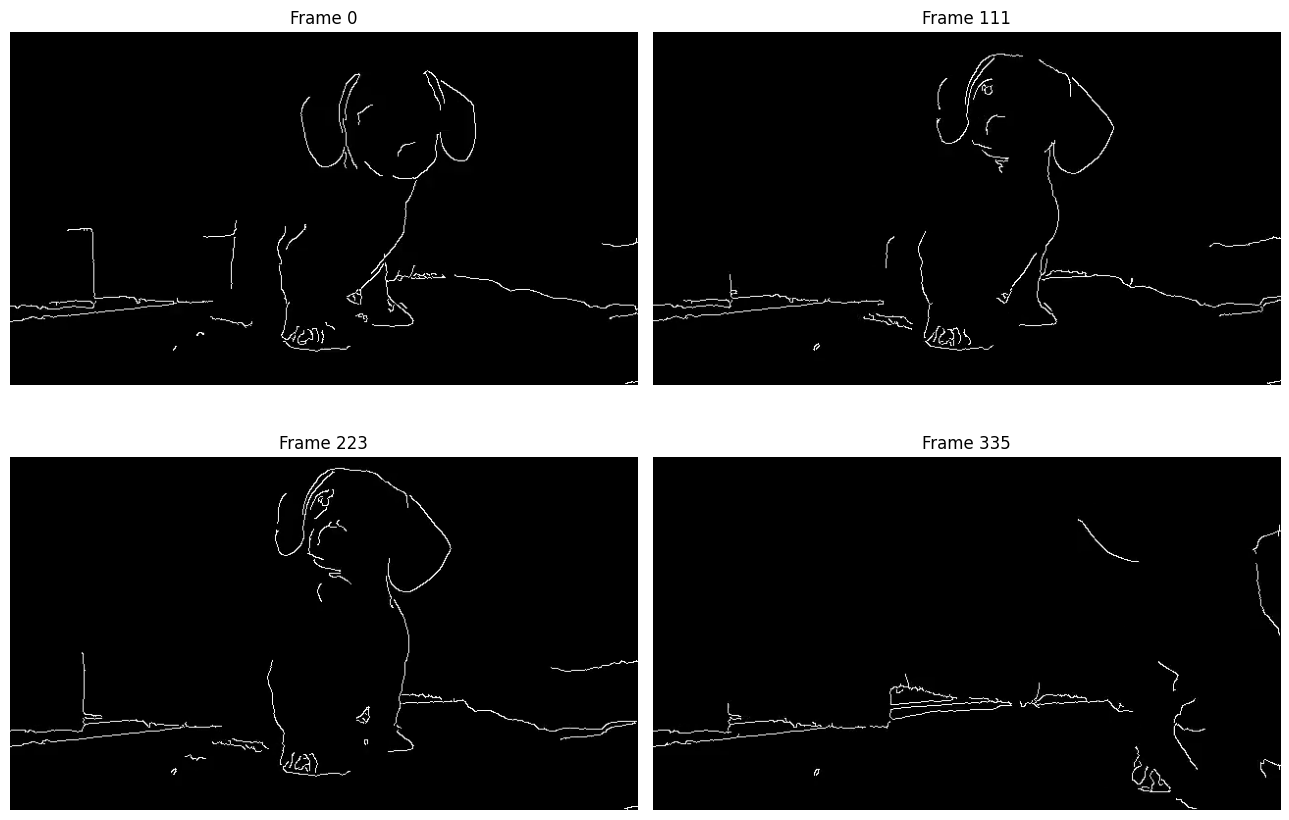

In [ ]:
for output_path in exported_videos:
    output_info = get_video_info(output_path)
    print('\n' + '=' * 60)
    print_video_info(output_path, output_info)

first_output_path = exported_videos[0]
output_sample_frames = extract_sample_frames(
    first_output_path,
    number_of_frames=4
)
show_frames(
    output_sample_frames,
    columns=2,
    figure_width=13
)

## 14. تشغيل الفيديو داخل Colab — اختياري

عرض الفيديو بطريقة `embed=True` يضع بيانات الفيديو داخل مخرجات الدفتر، وهذا قد يجعل حفظ الدفتر بطيئًا جدًا مع الإنترنت لديك. لذلك الخيار التالي معطل افتراضيًا.

إذا احتجت المعاينة داخل الدفتر، غيّر `EMBED_VIDEO_PREVIEW` إلى `True` ثم شغّل الخلية. بعد المشاهدة استخدم `Edit → Clear all outputs` قبل الحفظ.

In [ ]:
EMBED_VIDEO_PREVIEW = False

if EMBED_VIDEO_PREVIEW:
    from IPython.display import Video, display
    display(Video(str(first_output_path), embed=True))
else:
    print('تم تعطيل تضمين الفيديو للمحافظة على صغر حجم الدفتر.')
    print('يمكن مشاهدة الملف مباشرة من مجلد النتائج في Google Drive:')
    print(first_output_path)

تم تعطيل تضمين الفيديو للمحافظة على صغر حجم الدفتر.
يمكن مشاهدة الملف مباشرة من مجلد النتائج في Google Drive:
/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/06_Video_Processing/dog_canny.mp4


## 15. ملاحظات مهمة

1. OpenCV يقرأ ويكتب الصورة فقط، ولا ينقل المسار الصوتي بنفسه.
2. دالة `finalize_mp4` تستخدم FFmpeg لإعادة ترميز الفيديو إلى H.264 وإضافة الصوت الأصلي إن وُجد.
3. تقليل دقة الفيديو يزيد سرعة المعالجة ويقربنا من المعالجة في الزمن الحقيقي.
4. إذا كانت `processing_fps` أكبر من أو مساوية لـFPS الأصلي، فالخوارزمية قادرة نظريًا على مجاراة سرعة الفيديو على الجهاز نفسه.
5. نتائج السرعة في Colab لا تساوي بالضرورة سرعة هاتف Android؛ لذلك سنعيد القياس على الهاتف لاحقًا.

## 16. الربط بتطبيق Android

| Python/Colab | Android | المهمة |
|---|---|---|
| `cv2.VideoCapture` | Media3 / `MediaExtractor` أو إطارات CameraX | قراءة الفيديو والإطارات |
| `cv2.VideoWriter` | MediaCodec / Media3 Transformer | ترميز الفيديو الناتج |
| `process_frame` | دالة تستقبل `Mat` وتعيد `Mat` | تطبيق الفلتر على كل إطار |
| `cv2.cvtColor` | `Imgproc.cvtColor` | Grayscale وHSV |
| `cv2.GaussianBlur` | `Imgproc.GaussianBlur` | التنعيم |
| `cv2.Canny` | `Imgproc.Canny` | اكتشاف الحواف |
| `cv2.threshold` | `Imgproc.threshold` | التقسيم بالعتبة |
| `cv2.HoughLinesP` | `Imgproc.HoughLinesP` | اكتشاف الخطوط |

سنفصل في تطبيق Android بين واجهة المستخدم ومحرك معالجة الإطار، حتى نستخدم دالة المعالجة نفسها للصور والفيديو والكاميرا المباشرة، وكل ذلك دون إنترنت.

## 17. أسئلة للمناقشة والتقرير

1. لماذا يجب أن تكون أبعاد كل الإطارات المكتوبة متساوية؟
2. ما الفرق بين FPS الخاص بالفيديو و`processing_fps`؟
3. لماذا يحول Canny الناتج إلى BGR قبل كتابته في الفيديو؟
4. لماذا لا يحتفظ `cv2.VideoWriter` بالصوت؟
5. كيف يؤثر تقليل الدقة على السرعة والجودة؟
6. أي الخوارزميات كانت الأقرب إلى الزمن الحقيقي؟
7. كيف ستتغير المعالجة عند تطبيقها على كاميرا مباشرة؟

> بعد التأكد من حفظ النتائج، استخدم `Edit → Clear all outputs` لتقليل حجم الدفتر وتسريع حفظه.

**الخطوة التالية:** الدفتر `07_Live_Camera_Processing.ipynb` لمعالجة إطارات الكاميرا مباشرة.